# ДЗ 1: Казань — кварталы и показатели города

**Казань, Республика Татарстан, Россия · BlocksNet 1.0.0a9 · Windows / Python 3.12**

Ноутбук подготовлен с помощью OpenCode и проверен перед первым запуском.
Уже подготовлены и сохранены **5159 кварталов Казани**. Следующий этап — расчёт показателей; их результатов пока нет.

**На первом проходе запускай по одной ячейке только до раздела «ОСТАНОВКА ДЛЯ ПРОВЕРКИ».**
Ячейка — прямоугольный блок с кодом. Нажми ▶ слева от него или Shift+Enter.
Сначала выбери справа вверху ядро **Python 3.12 (urban-ai-practice)** / `.venv`.

План: граница → дороги, ЖД и вода → кварталы → проверка карты → обсуждение метрик →
землепользование → готовый дорожный граф и время в пути → здания и население → школы →
обеспеченность → плотность → Spacematrix и «Стрелка» → доступность с учётом площади →
сохранение результатов → отдельный этап создания dashboard.html и публикации в GitHub.

Исследуем найденную административную границу всей Казани. Готовую дорожную сеть Overture скачиваем для города с запасом; её охват и подходы проверяются отдельно. При недостаточном покрытии
расчёт остановится: менять границу или способ расчёта без обсуждения не нужно.

Источники: [задание](https://mvin8.github.io/ai-technologies-in-urbanism/content/practice/practice-02.html),
[пример BlocksNet](https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb),
[OpenStreetMap](https://www.openstreetmap.org/copyright),
[готовая дорожная сеть](https://docs.overturemaps.org/guides/transportation/).

Транспортный сценарий — **автомобильный граф, без пробок**; его результаты нельзя называть
пешеходной доступностью или проверкой местных нормативов. Неизвестные этажность, население
и вместимость школ отмечаются как модельные оценки.

# 📖 Показатели BlocksNet простыми словами

Сначала мы получили кварталы. Теперь узнаем, чем они отличаются друг от друга.
Ниже — все восемь групп из `references/pipeline_reference.ipynb` для нашей версии **1.0.0a9**.

| Группа | Что узнаем о Казани | Основные единицы |
|---|---|---|
| Землепользование | Что преобладает: жильё, деловая функция, промышленность, зелёные территории, транспорт, сельское хозяйство или специальная функция | Категория и доли 0–1 |
| Время в пути | Сколько занимает поездка между кварталами по выбранному готовому графу | Минуты |
| Здания и население | Сколько зданий, каковы их площади и этажность, сколько жителей даёт модель | Здания, м², этажи, человек |
| Школы | Сколько объектов школ и сколько в них мест | Школы и места |
| Обеспеченность школами | Хватает ли мест с учётом населения, времени в пути и конкуренции за школы | Человек/места и доли 0–1 |
| Плотность | Сколько территории занято зданиями и насколько интенсивно она застроена | Отношения площадей, средняя этажность |
| Типы застройки | Какие группы кварталов выделяют Spacematrix и правила «Стрелки» | Номер кластера и категория |
| Доступность с учётом площади | Каково среднее время до кварталов, если более крупные кварталы имеют больший вес | Минуты |

## Землепользование

В каждом квартале сохраняются семь долей функций, преобладающая функция `land_use` и её доля `share`.
Пробелы в OSM остаются неизвестными значениями. Дополнительная сводка по городу показывает долю
площади кварталов каждого преобладающего типа; это не точная доля всех земельных участков.

## Время в пути

Матрица — таблица «откуда × куда». Для этой работы выбран **автомобильный граф, без пробок**.
Подход к ближайшему узлу оценивается отдельно по прямой со скоростью 5 км/ч.
Это модельное время; его нельзя называть пешеходной доступностью или проверкой нормативов.

## Здания и население

Сохраняются число зданий, площадь пятна `footprint_area`, этажность `number_of_floors`, площадь
этажей `build_floor_area`, жилая `living_area` и нежилая `non_living_area` площади, признак жилого
здания `is_living` и `population`. Если этажность неизвестна, принимается **1 этаж**. Население
оценивается из жилой площади с допущением **30 м² на человека** и коэффициентом полезной площади
**0,9**. Это оценка по модели, не перепись населения; признаки восстановленных данных сохраняются.

## Школы и обеспеченность

Мы исследуем школы. Неизвестная вместимость оценивается в **250 мест** и отмечается отдельно.
Параметры примера: **120 мест на 1000 жителей**, порог **15 минут** для нашего транспортного сценария.

- `demand`, `capacity` — потребность и вместимость; `demand_left`, `capacity_left` — их остатки.
- `demand_within`, `capacity_within` — распределение в пределах порога;
  `demand_without`, `capacity_without` — распределение за его пределами.
- `provision_strong` — доля потребности, обеспеченная в пределах порога.
- `provision_weak` — доля потребности, обеспеченная всем распределением, включая внешнюю зону.
  При `max_depth=1` внешняя зона не расширяется и оба показателя могут совпасть.
- `links` — модельное распределение между кварталами. Это не наблюдения о реальных поездках людей;
  прямые линии на карте не являются маршрутами по улицам.

## Все семь показателей плотности

| Поле | Смысл |
|---|---|
| `fsi` | Площадь всех этажей / площадь квартала |
| `gsi` | Пятно зданий / площадь квартала; доля 0–1 |
| `mxi` | Жилая площадь / площадь всех этажей; доля 0–1 |
| `l` | Площадь этажей / пятно зданий; средняя этажность |
| `osr` | Незастроенная площадь квартала / площадь всех этажей |
| `share_living` | Жилая площадь / пятно зданий |
| `share_non_living` | Нежилая площадь / пятно зданий |

В этой версии последние два показателя могут превышать 1. Площади измеряются в м²,
их отношения — безразмерные. Эти показатели не равны числу жителей на гектар.

## Два способа выделить типы застройки

Spacematrix группирует кварталы по **L, FSI, MXI**. Сохраняем номер кластера, название типа и
характеристики групп. «Стрелка» применяет отдельные правила к характеристикам застройки.
Результаты двух способов могут различаться. Кварталы без определимых значений остаются без типа.

## Доступность с учётом площади

`area_accessibility` — среднее время до кварталов с весами по площади квартала назначения.
Здесь это автомобильные минуты. Это не время до одной точки центра. Чем меньше значение,
тем меньше средняя удалённость от площади исследуемой территории.

Расчёты этих показателей ещё не выполнены. Источники, допущения и пропуски нужно учитывать
при выводах; реальные выводы напишем после появления результатов.

In [6]:
# ЯЧЕЙКА 1: только импорты и настройки. Данные города не скачиваются.
import os
import sys
import json
from pathlib import Path
from importlib.metadata import version
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import osmnx as ox
from IPython.display import display

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists()), None)
if PROJECT is None:
    raise RuntimeError('Открой ноутбук из папки учебного проекта urban-ai-practice.')
sys.path.insert(0, str(PROJECT))
import importlib
import my_package.kazan_support as kazan_support
importlib.reload(kazan_support)
from my_package.kazan_support import (
    fetch_boundary, fetch_features, read_layer, save_layer, inspect_map, plot_columns,
    reusable, stamp, numeric, deduplicate_schools, write_json,
    download_ready_graph, prepare_drive_graph, graph_coverage, provision_links_geojson,
)
assert sys.version_info[:2] == (3, 12), 'Выбери ядро Python 3.12 из .venv проекта.'
assert version('blocksnet') == '1.0.0a9', 'Нужна версия BlocksNet 1.0.0a9.'
DATA_DIR = str(PROJECT / 'examples' / 'data')
os.makedirs(DATA_DIR, exist_ok=True)
CITY_NAME = 'Казань, Республика Татарстан, Россия'
pd.set_option('display.max_columns', 40)
ox.settings.use_cache = True
ox.settings.cache_folder = str(Path(DATA_DIR) / 'osm_cache')
ox.settings.requests_timeout = 300
plt.rcParams['font.family'] = 'DejaVu Sans'
POLYGONS = ['Polygon', 'MultiPolygon']
LINES = ['LineString', 'MultiLineString']
BASE = ['osm_type', 'osm_id', 'name']
FORCE_RECALCULATE = False

MAP_AND_METRICS_CHECKED = False

def require_review():
    if not MAP_AND_METRICS_CHECKED:
        raise RuntimeError('Сначала выполни короткую ячейку под разделом «Проверка кварталов и переход к показателям».')

def datafile(name):
    return Path(DATA_DIR) / name

print('OK: библиотеки импортированы')
print('Python:', sys.version.split()[0], '| BlocksNet:', version('blocksnet'))
print('Данные и результаты будут здесь:', DATA_DIR)

OK: библиотеки импортированы
Python: 3.12.10 | BlocksNet: 1.0.0a9
Данные и результаты будут здесь: c:\Users\Vlada\Documents\Codex\2026-10-27\new-chat\outputs\urban-ai-practice\examples\data


## 1. Границы Казани

Скачиваем административную границу города из OSM и сохраняем в GeoJSON.
Система координат после перевода — метрическая (метры).

In [2]:
# Первая загрузка: только граница города. Повторный запуск читает сохранённый файл.
boundary_wgs = fetch_boundary(CITY_NAME, datafile('kazan_boundaries.geojson'))
crs = boundary_wgs.estimate_utm_crs()
boundaries = boundary_wgs.to_crs(crs)
print('Найдено:', boundary_wgs.get('display_name', pd.Series([CITY_NAME])).iloc[0])
print(f'Площадь найденной границы: {boundaries.area.sum() / 1e6:,.1f} км²; CRS: {crs}')
display(inspect_map({'Граница Казани': boundary_wgs}, datafile('kazan_boundary_preview.html')))

Найдено: Kazan, городской округ Казань, Tatarstan, Volga Federal District, Russia
Площадь найденной границы: 594.5 км²; CRS: EPSG:32639


## 2. Сырые городские объекты (вода, дороги, железные дороги)

Из OSM скачиваем геометрии, по которым потом будем резать кварталы:
а) воду — реки (Казанка, Волга), озёра, каналы;
б) дороги — основные типы улиц;
в) железные дороги.

Дольше всё в метрическую СКР. Единицы — метры, м².

In [8]:
# Обновляем загрузчик после исправления ошибки 502. Ядро перезапускать не нужно.
import importlib
import my_package.kazan_support as kazan_support
importlib.reload(kazan_support)
fetch_features = kazan_support.fetch_features

# OSM ожидает широту/долготу. Все вычисления геометрии выполняются затем в метрах.
bc_tags = {
    'water': {'natural': ['water', 'bay'], 'waterway': ['river', 'canal', 'ditch'],
              'water': True, 'landuse': ['basin', 'reservoir']},
    'roads': {'highway': ['construction', 'living_street', 'motorway', 'motorway_link',
              'pedestrian', 'primary', 'primary_link', 'residential', 'road', 'secondary',
              'secondary_link', 'tertiary', 'tertiary_link', 'track', 'trunk', 'trunk_link', 'unclassified']},
    'railways': {'railway': 'rail'},
}
TAGS_BY_GEOM = {'water': POLYGONS + LINES, 'roads': LINES, 'railways': LINES}
urban_objects = {}
for key, tags in bc_tags.items():
    print('Читаем или загружаем:', key)
    frame = fetch_features(boundary_wgs, tags, datafile(f'kazan_raw_{key}.geojson'),
        BASE, TAGS_BY_GEOM[key], allow_empty=(key != 'roads')).to_crs(crs)
    urban_objects[key] = frame
    print(key, len(frame), 'объектов')
display(inspect_map({'Вода': urban_objects['water'], 'Дороги': urban_objects['roads'],
                    'Железные дороги': urban_objects['railways']}, datafile('kazan_objects_preview.html')))

Читаем или загружаем: water
water 432 объектов
Читаем или загружаем: roads
roads 10776 объектов
Читаем или загружаем: railways
Сервер OSM: https://overpass-api.de/api
railways 805 объектов


In [9]:
# Эти файлы уже сохранены во время загрузки. Рядом записаны источник, запрос и дата получения.
for key in urban_objects:
    print(datafile(f'kazan_raw_{key}.geojson'))

c:\Users\Vlada\Documents\Codex\2026-10-27\new-chat\outputs\urban-ai-practice\examples\data\kazan_raw_water.geojson
c:\Users\Vlada\Documents\Codex\2026-10-27\new-chat\outputs\urban-ai-practice\examples\data\kazan_raw_roads.geojson
c:\Users\Vlada\Documents\Codex\2026-10-27\new-chat\outputs\urban-ai-practice\examples\data\kazan_raw_railways.geojson


## 3. Нарезка кварталов

`preprocess_urban_objects` готовит линии и полигоны, `cut_urban_blocks` делит территорию на кварталы.
Плоскости дорог, ЖД и воды become границами кварталов.

In [10]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

block_path = datafile('kazan_blocks.geojson')
cut_deps = [datafile('kazan_boundaries.geojson')] + [datafile(f'kazan_raw_{k}.geojson') for k in bc_tags]
if reusable([block_path], cut_deps, {'cut_version': 1}, force=FORCE_RECALCULATE):
    blocks = read_layer(block_path, crs, 'block_id')
    print('Прочитаны сохранённые кварталы.')
else:
    lines, polygons = preprocess_urban_objects(urban_objects['roads'], urban_objects['railways'], urban_objects['water'])
    blocks = cut_urban_blocks(boundaries.copy(), lines, polygons).reset_index(drop=True)
    if blocks.empty or not blocks.geometry.is_valid.all() or (blocks.area <= 0).any():
        raise ValueError('Нужна проверка геометрии кварталов перед расчётами.')
    save_layer(blocks, block_path, 'block_id')
    stamp([block_path], cut_deps, {'cut_version': 1})
print(f'Кварталов: {len(blocks)}')
print(f'Площадь кварталов: {blocks.area.sum() / 1e4:,.0f} га; медиана: {blocks.area.median() / 1e4:,.2f} га')
display(inspect_map({'Кварталы': blocks, 'Дороги': urban_objects['roads'],
                    'Вода': urban_objects['water']}, datafile('kazan_blocks_preview.html')))
print('Кварталы сохранены:', block_path)

c:\Users\Vlada\Documents\Codex\2026-10-27\new-chat\outputs\urban-ai-practice\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
2026-10-27 23:48:48.105 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-27 23:48:48.118 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-10-27 23:48:48.122 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema
2026-10-27 23:48:48.135 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema
2026-10-27 23:48:48.140 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema
2026-10-27 23:48:48.159 | INFO     | blocksnet.blocks.cutting.proc

Кварталов: 5159
Площадь кварталов: 52,545 га; медиана: 1.60 га


Кварталы сохранены: c:\Users\Vlada\Documents\Codex\2026-10-27\new-chat\outputs\urban-ai-practice\examples\data\kazan_blocks.geojson


## ✅ Проверка кварталов и переход к показателям

Технически проверены сохранённые **5159 кварталов**: геометрии корректны, пустых и нулевых
площадей нет, идентификаторы уникальны, контрольные точки находятся внутри границы Казани.
На карте показаны аналитические кварталы, их границы могут отличаться от официальных.

Объяснение всех восьми групп показателей находится в справочнике в начале ноутбука.
Прочитай его перед расчётами. Далее запускай ячейки по одной: сначала короткую ячейку ниже,
затем раздел **4. Функциональные зоны**. Завершив раздел 4, остановись перед разделом 5:
проверим полученную карту и перейдём к готовому транспортному графу.

Для подложки нужен интернет. Карта внутри VS Code показывается через локальный просмотр HTML;
при новом запуске он включается во время отображения карты. HTML-файлы остаются в `examples/data`.

In [12]:
MAP_AND_METRICS_CHECKED = True

def require_review():
    if not MAP_AND_METRICS_CHECKED:
        raise RuntimeError('Сначала проверь карту кварталов и обсуди показатели. На первом проходе остановись здесь.')

print('Можно продолжать.' if MAP_AND_METRICS_CHECKED else 'Остановка: карта и показатели ещё не проверены.')
print('Следующий шаг: первая ячейка раздела 4 «Функциональные зоны».')

Можно продолжать.
Следующий шаг: первая ячейка раздела 4 «Функциональные зоны».


## 4. Функциональные зоны

Основной и резервные серверы Overpass не ответили (502, таймаут, 504). Поэтому для оставшихся
трёх слоёв используем [готовую выгрузку Татарстана OpenStreetMap France](https://download.openstreetmap.fr/extracts/russia/volga_federal_district/).
Она скачивается один раз (**около 96 МБ**). Прогресс отображается в мегабайтах, целостность проверяется
по контрольной сумме издателя; после обрыва повторный запуск продолжает полученную часть.

Далее локально выбираются **только объекты, пересекающие сохранённую границу Казани**:
землепользование, здания и школы. Целые геометрии и отверстия полигонов сохраняются.
Слои записываются в GeoJSON, а источник, дата выгрузки и параметры — рядом в `source.json`.
Существующие кварталы, дороги, вода и ЖД сохраняются. Временные срезы OSM могут отличаться:
точные даты источников нужно учитывать при выводах.

Запусти следующую ячейку и дождись таблицы и строки **«Полигонов землепользования: …»**.
Во время чтения локального файла дополнительно появятся числа подготовленных зданий и школ.
После этого выполняй ячейки раздела 4 по очереди: они определят преобладающую функцию каждого
квартала и её долю. Если выгрузку прочитать не удастся, расчёт остановится с сообщением.


In [14]:
# ЗАГРУЗКА БЕЗ OVERPASS: один готовый файл Татарстана, затем выбор объектов Казани.
# Повторно запускай эту же ячейку: полученная часть файла сохраняется при обрыве.
import importlib
import my_package.kazan_support as kazan_support
import my_package.regional_osm as regional_osm
importlib.reload(kazan_support)
importlib.reload(regional_osm)
fetch_features = kazan_support.fetch_features

require_review()

from blocksnet.enums import LandUse
functional_raw = fetch_features(boundary_wgs, {'landuse': True}, datafile('kazan_raw_landuse.geojson'),
    BASE + ['landuse'], POLYGONS).to_crs(crs)
functional_zones = functional_raw[['geometry', 'landuse']].reset_index(drop=True)
print('Полигонов землепользования:', len(functional_zones))
display(functional_zones.head())

Скачиваем готовый файл Татарстана (около 96 МБ).
  Получено 1.0 / 96.4 МБ
  Получено 6.3 / 96.4 МБ
  Получено 11.5 / 96.4 МБ
  Получено 16.8 / 96.4 МБ
  Получено 22.0 / 96.4 МБ
  Получено 27.3 / 96.4 МБ
  Получено 32.5 / 96.4 МБ
  Получено 37.7 / 96.4 МБ
  Получено 43.0 / 96.4 МБ
  Получено 48.2 / 96.4 МБ
  Получено 53.5 / 96.4 МБ
  Получено 58.7 / 96.4 МБ
  Получено 64.0 / 96.4 МБ
  Получено 69.2 / 96.4 МБ
  Получено 74.4 / 96.4 МБ
  Получено 79.7 / 96.4 МБ
  Получено 84.9 / 96.4 МБ
  Получено 90.2 / 96.4 МБ
  Получено 95.4 / 96.4 МБ
Файл скачан; контрольная сумма совпала.
Читаем локальный файл: готовим землепользование, здания и школы Казани.
Файл читается дважды для сборки полигонов с отношениями и отверстиями.
  Прочитано узлов региона: 1,000,000
  Прочитано узлов региона: 2,000,000
  Прочитано узлов региона: 3,000,000
  Прочитано узлов региона: 4,000,000
  Прочитано узлов региона: 5,000,000
  Прочитано узлов региона: 6,000,000
  Прочитано узлов региона: 7,000,000
  Прочитано узлов

,geometry,landuse
0,"MULTIPOLYGON (((378180.055 6190151.212, 378198...",industrial
1,"MULTIPOLYGON (((366219.266 6192256.627, 366412...",residential
2,"MULTIPOLYGON (((378742.868 6187609.255, 378839...",residential
3,"MULTIPOLYGON (((386489.065 6192683.532, 386523...",residential
4,"MULTIPOLYGON (((387157.025 6191955.093, 387292...",residential


Нераспознанных полигонов: 86


,Количество кварталов
Функция квартала,
Жилая,2301
Не определено,2002
Рекреационная,367
Сельскохозяйственная,174
Промышленная,158
Специальная,97
Деловая,60


,Доля: Жилая,Доля: Деловая,Доля: Рекреационная,Доля: Промышленная,Доля: Транспортная,Доля: Специальная,Доля: Сельскохозяйственная,Функция квартала,Доля преобладающей функции
Номер квартала,,,,,,,,,
0,0.133392,0.000000,0.000247,0.030834,0.0,0.0,0.0,Жилая,0.133392
1,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,Не определено,NaN
2,0.311100,0.000000,0.000000,0.000000,0.0,0.0,0.0,Жилая,0.311100
3,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,Не определено,NaN
4,0.112707,0.161585,0.025239,0.006248,0.0,0.0,0.0,Деловая,0.161585


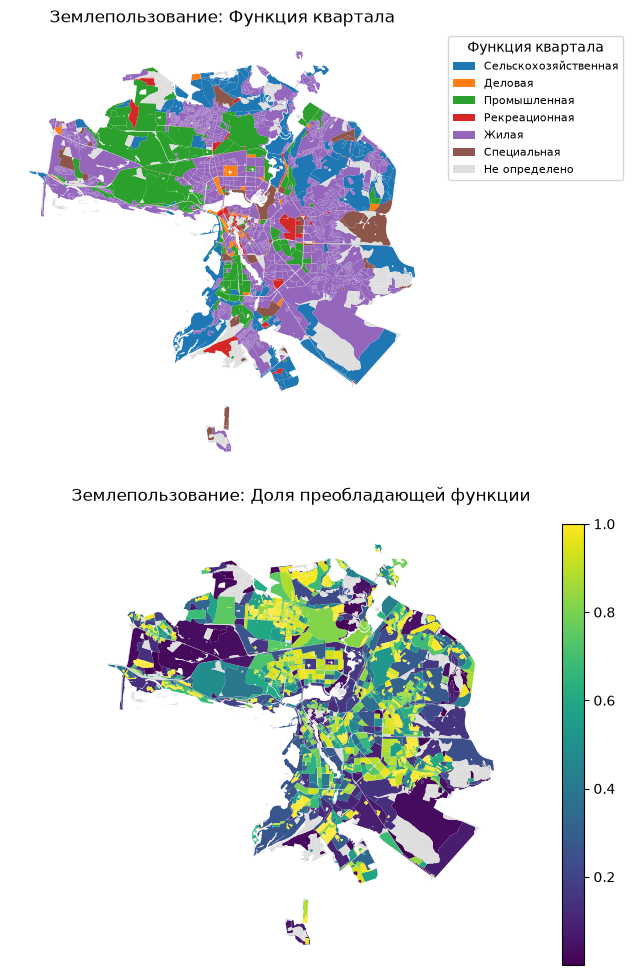

In [20]:
# Карта и таблицы с русскими подписями
import importlib
import my_package.kazan_support as kazan_support
importlib.reload(kazan_support)
plot_columns = kazan_support.plot_columns
landuse_table_ru = kazan_support.landuse_table_ru
land_use_label = kazan_support.land_use_label

require_review()

rules = {
    "commercial": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL,
    "cemetery": LandUse.SPECIAL,
    "garages": LandUse.INDUSTRIAL,
    "residential": LandUse.RESIDENTIAL,
    "retail": LandUse.BUSINESS,
    "grass": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "construction": LandUse.SPECIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "forest": LandUse.RECREATION,
    "allotments": LandUse.AGRICULTURE,
    "quarry": LandUse.SPECIAL,
    "village_green": LandUse.RECREATION,
    "greenfield": LandUse.SPECIAL,
    "recreation_ground": LandUse.RECREATION,
    "education": LandUse.BUSINESS,
    "religious": LandUse.SPECIAL,
    "reservoir": LandUse.SPECIAL,
    "landfill": LandUse.SPECIAL,
}

from blocksnet.blocks.assignment import assign_land_use


recognized = functional_zones[functional_zones.landuse.isin(rules)].copy()
print('Нераспознанных полигонов:', len(functional_zones) - len(recognized))
if recognized.empty:
    raise ValueError('Нет распознаваемых зон. Нужна проверка исходных данных и правил.')
# Объединяем пересекающиеся полигоны одной функции: одна площадь учитывается один раз.
zones_by_function = recognized[['landuse','geometry']].copy()
zones_by_function['functional_zone'] = zones_by_function.landuse.map(lambda tag: rules[tag].value)
zones_by_function = zones_by_function[['functional_zone','geometry']].dissolve(by='functional_zone',as_index=False)
zones_by_function = zones_by_function.explode(ignore_index=True)
rules_by_function = {value.value:value for value in LandUse}
assigned = assign_land_use(blocks[['geometry']].copy(), zones_by_function, rules_by_function)
function_columns = [value.value for value in LandUse if value.value in assigned.columns]
if (assigned[function_columns] > 1+1e-6).any().any():
    raise ValueError('Доля функции выше 1: нужна проверка геометрии исходных полигонов.')
assigned[function_columns] = assigned[function_columns].clip(0,1)
assigned['share'] = assigned['share'].clip(0,1)
assigned['land_use'] = assigned.land_use.map(lambda x: x.value if isinstance(x, LandUse) else x)
blocks = assigned
counts_ru = blocks.land_use.map(land_use_label).value_counts().rename('Количество кварталов')
display(counts_ru.rename_axis('Функция квартала').to_frame())
display(landuse_table_ru(blocks).head())
plot_columns(blocks, ['land_use', 'share'], 'Землепользование');

In [21]:
require_review()

save_layer(blocks, datafile('kazan_blocks_landuse.geojson'), 'block_id')
print('Сохранены функция, доля преобладающей функции и все семь долей землепользования.')

Сохранены функция, доля преобладающей функции и все семь долей землепользования.


,Функция квартала,"Доля площади, %","Площадь, м²"
0,Жилая,40.74,2.140712e+08
6,Сельскохозяйственная,19.58,1.028621e+08
3,Промышленная,19.24,1.010967e+08
7,Не определено,11.41,5.997547e+07
5,Специальная,5.18,2.723927e+07
2,Рекреационная,2.65,1.393532e+07
1,Деловая,1.19,6.270090e+06
4,Транспортная,0.00,0.000000e+00


Раздел 4 завершён. Сохрани ноутбук Ctrl+S и покажи карту перед разделом 5.


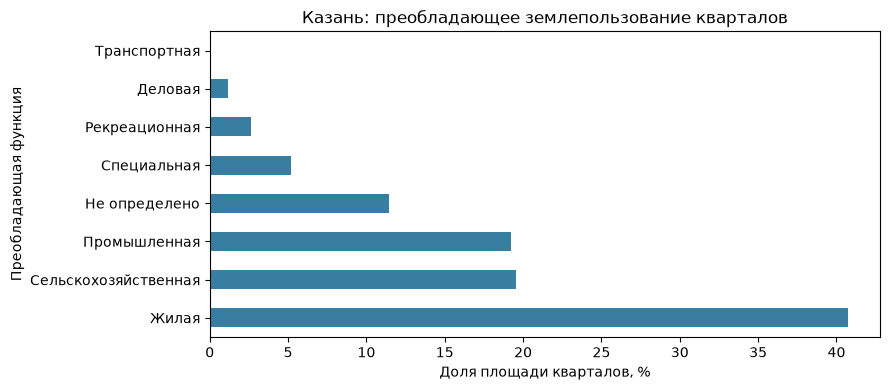

In [22]:
require_review()

# Дополнительно: доли ПЛОЩАДИ кварталов по их преобладающей функции.
from blocksnet.analysis.land_use import calculate_land_use_shares

share_input = blocks[['land_use']].copy()
share_input['land_use'] = share_input.land_use.astype(object).where(share_input.land_use.notna(), None)
share_input['site_area'] = blocks.area.astype(float)
total_area = float(share_input.site_area.sum())
if total_area <= 0:
    raise ValueError('Для сводки нужна положительная площадь кварталов.')
shares = calculate_land_use_shares(share_input)
labels = {'residential':'Жилая', 'business':'Деловая', 'industrial':'Промышленная',
          'recreation':'Рекреационная', 'transport':'Транспортная',
          'agriculture':'Сельскохозяйственная', 'special':'Специальная'}
share_rows = [{'land_use':lu.value, 'label_ru':labels.get(lu.value,lu.value),
               'land_use_share':float(value), 'area_m2':float(value)*total_area}
              for lu,value in shares.items()]
unknown_share = float(share_input.loc[share_input.land_use.isna(), 'site_area'].sum()/total_area)
share_rows.append({'land_use':'unknown', 'label_ru':'Не определено',
                   'land_use_share':unknown_share, 'area_m2':unknown_share*total_area})
shares_df = pd.DataFrame(share_rows).sort_values('land_use_share',ascending=False)
if not np.isclose(shares_df.land_use_share.sum(),1.0):
    raise ValueError('Проверь полноту категорий землепользования: сумма долей не равна 1.')
shares_df['percent'] = shares_df.land_use_share*100
display(shares_df[['label_ru','percent','area_m2']].rename(columns={
    'label_ru':'Функция квартала', 'percent':'Доля площади, %', 'area_m2':'Площадь, м²'}).round(2))
shares_df.set_index('label_ru')['percent'].plot.barh(figsize=(9,4), color='#377ea0')
plt.xlabel('Доля площади кварталов, %')
plt.ylabel('Преобладающая функция')
plt.title('Казань: преобладающее землепользование кварталов')
plt.tight_layout()
shares_df.set_index('land_use').to_csv(datafile('kazan_land_use_shares.csv'))
print('Раздел 4 завершён. Сохрани ноутбук Ctrl+S и покажи карту перед разделом 5.')

## 5. Готовая дорожная сеть и время в пути

**Территория остаётся прежней: вся Казань.** Старый файл Harvard Dataverse охватывает меньшую
городскую застройку: 1532 квартала оказались дальше 1 км от его узлов. Файл сохранён, но для
дальнейшего расчёта не используется.

Новый источник — [Overture Transportation](https://docs.overturemaps.org/guides/transportation/),
выпуск **2026-10-21.0**. Скачиваются готовые дорожные сегменты и узлы (connectors) для города
с 20-км запасом вокруг границы. Связи берутся **только из опубликованных идентификаторов узлов**:
пересечения линий сами по себе не создают соединения, интермодальный граф не строится.
Данные переводятся в формат NetworkX/BlocksNet и сохраняются для повторного использования.

1. Выполни **5А**. Дождись строки **«Сеть Overture скачана и сохранена»**.
2. Выполни **5Б**. Она подготовит автомобильную сеть, проверит охват, покажет длины подходов,
   затем рассчитает и сохранит матрицу времени. Это более долгий шаг.

Сценарий **автомобильный, без пробок**. Учитываются классы дорог и простые ограничения въезда
и направления. Время оценивается по ограничениям скорости, а при их отсутствии — по классу дороги.
Сложные повороты, условия по времени суток и специальные разрешения полностью не моделируются.
Используется крупнейшая сильносвязная автомобильная компонента; исключённые узлы отражаются в
метаданных. Топология и скорости не являются проверкой маршрутов для навигации.

Подход от контрольной точки квартала к ближайшему узлу и отход от него оцениваются по прямой
со скоростью **5 км/ч**. **1 км — диагностическая отметка, не запрет и не норматив.** Для новой
сети с широким охватом длинный подход может означать удалённость от дороги внутри большого квартала.
Такие кварталы остаются в расчёте, а длины подходов сохраняются отдельно. Если сама рамка связной
сети меньше территории или есть недостижимые пары, выполнение останавливается.

Источники и ограничения сохраняются в `kazan_overture_drive.graphml.source.json`.
Диагностика подходов — `kazan_overture_connector_diagnostics.geojson`. Для повторного запуска
используются сохранённые файлы; при удалении старого выпуска с сервера потребуется обновить
номер версии осознанно, а не подменять данные незаметно.

Совместимость с установленной IduEdu 0.4.1: перед матрицей номера узлов приводятся к порядку строк разреженной матрицы, для параллельных рёбер выбирается минимальное время. Это не меняет направления и связность дорог. Подходы добавляются явно для всех пар разных кварталов, включая пары с одним ближайшим узлом; диагональ (тот же квартал) равна нулю.

In [24]:
# 5А. СКАЧАТЬ ГОТОВУЮ ДОРОЖНУЮ СЕТЬ ДЛЯ ВСЕЙ КАЗАНИ
require_review()
import importlib
import my_package.overture_network as overture_network
importlib.reload(overture_network)

overture_segment_path, overture_connector_path = overture_network.download_overture_network(
    boundary_wgs, Path(DATA_DIR))
print('Сеть Overture скачана и сохранена. Далее — ячейка 5Б.')

Overture 2026-10-21.0: загружаем segment для Казани и 20-км запаса.
Сначала читается индекс файлов; затем появится число полученных объектов.
  segment: получено 2 объектов
  segment: получено 3 объектов
  segment: получено 4 объектов
  segment: получено 1,312 объектов
  segment: получено 20,659 объектов
  segment: получено 26,542 объектов
  segment: получено 42,509 объектов
  segment: получено 64,149 объектов
  segment: получено 68,926 объектов
  segment: получено 90,492 объектов
  segment: получено 94,113 объектов
  segment: получено 95,161 объектов
  segment: получено 95,162 объектов
Overture 2026-10-21.0: загружаем connector для Казани и 20-км запаса.
Сначала читается индекс файлов; затем появится число полученных объектов.
  connector: получено 16,718 объектов
  connector: получено 39,450 объектов
  connector: получено 49,765 объектов
  connector: получено 101,837 объектов
  connector: получено 144,814 объектов
  connector: получено 148,324 объектов
Сеть Overture скачана и сохране

In [26]:
# 5Б. ПРОВЕРИТЬ СЕТЬ И РАССЧИТАТЬ ВРЕМЯ МЕЖДУ КВАРТАЛАМИ
require_review()
if 'overture_segment_path' not in globals() or 'overture_connector_path' not in globals():
    raise RuntimeError('Сначала выполни ячейку 5А: скачивание сети Overture.')
import importlib
import my_package.routing_matrix as routing_matrix
importlib.reload(routing_matrix)
graph, graph_path = overture_network.prepare_overture_graph(
    overture_segment_path, overture_connector_path, crs, DATA_DIR)

# Проверяем пространственный охват новой связной сети, не меняя территорию.
points = blocks.representative_point()
node_x = np.array([d['x'] for _,d in graph.nodes(data=True)])
node_y = np.array([d['y'] for _,d in graph.nodes(data=True)])
inside_extent = (points.x.between(node_x.min()-1,node_x.max()+1)
                 & points.y.between(node_y.min()-1,node_y.max()+1))
if not inside_extent.all():
    raise ValueError('Рамка новой связной сети всё ещё меньше территории. Пришли результат проверки; кварталы не исключены.')

coverage = graph_coverage(blocks, graph, max_connector_m=1000).rename(columns={'graph_covered':'within_1km'})
coverage['connector_walk_min'] = coverage.connector_m/(5000/60)
save_layer(coverage, datafile('kazan_overture_connector_diagnostics.geojson'),'block_id')
far_count = int((~coverage.within_1km).sum())
print('Кварталов в исследовании:',len(blocks))
print('С подходом к ближайшему узлу более 1 км:',far_count)
print(f'Максимальный подход: {coverage.connector_m.max():,.0f} м')
if far_count:
    print('Длинные подходы отмечены в диагностике. Это прямолинейная модель, а не проверенные пешеходные маршруты.')
    display(coverage[['connector_m','connector_walk_min']].nlargest(5,'connector_m'))

matrix_path = datafile('kazan_acc_mx.parquet')
deps = [datafile('kazan_blocks.geojson'), graph_path, Path(routing_matrix.__file__)]
mx_params = {'mode':'drive','source':'Overture','release':overture_network.RELEASE,
             'first_last_mile':'straight line, 5 km/h','version':3,
             'matrix_adapter':'CSR node order; fastest parallel edge; approaches for every pair'}
print(f'Матрица {len(blocks)} × {len(blocks)}; минимум {len(blocks)**2*4/1024**2:.1f} МБ без накладных расходов.')
if reusable([matrix_path],deps,mx_params,force=FORCE_RECALCULATE):
    acc_mx = pd.read_parquet(matrix_path)
    acc_mx.index = acc_mx.index.astype(int)
    acc_mx.columns = acc_mx.columns.astype(int)
    print('Прочитана сохранённая матрица.')
else:
    print('Рассчитываем время. Дождись завершения ячейки.',flush=True)
    acc_mx = routing_matrix.calculate_drive_matrix(blocks,graph,dtype=np.float32,max_workers=2)
    if not np.isfinite(acc_mx.to_numpy()).all():
        raise ValueError('Есть недостижимые пары. Нужна проверка связности; значения не заменены выдуманным временем.')
    acc_mx.rename(columns=str).to_parquet(matrix_path)
    stamp([matrix_path],deps,mx_params)
acc_mx.to_csv(datafile('kazan_acc_mx.csv'))
travel_summary = pd.DataFrame({'travel_mean_min':acc_mx.mean(axis=1),'travel_median_min':acc_mx.median(axis=1)})
save_layer(blocks[['geometry']].join(travel_summary),datafile('kazan_travel_summary.geojson'),'block_id')
display(acc_mx.head())
print(f'Среднее время поездки с модельными подходами: {acc_mx.to_numpy().mean():.1f} мин')
print('Матрица времени рассчитана и сохранена. Далее — раздел 6: здания и население.')

Прочитан сохранённый автомобильный граф Overture.
Кварталов в исследовании: 5159
С подходом к ближайшему узлу более 1 км: 11
Максимальный подход: 1,532 м
Длинные подходы отмечены в диагностике. Это прямолинейная модель, а не проверенные пешеходные маршруты.


,connector_m,connector_walk_min
5105,1532.235812,18.386830
5104,1375.633273,16.507599
5127,1356.203867,16.274446
5128,1346.543591,16.158523
3634,1260.544541,15.126534


Матрица 5159 × 5159; минимум 101.5 МБ без накладных расходов.
Рассчитываем время. Дождись завершения ячейки.


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,...,5139,5140,5141,5142,5143,5144,5145,5146,5147,5148,5149,5150,5151,5152,5153,5154,5155,5156,5157,5158
0,0.000000,10.364214,27.158302,23.141716,24.747622,23.159958,18.918394,24.728859,21.842386,22.492533,27.614723,22.911163,22.688229,41.961727,40.245594,63.654575,38.008987,38.506905,38.853016,38.492226,...,26.493221,27.678831,27.448032,25.930462,27.162445,21.090256,22.755590,22.585440,22.026974,21.986881,21.896362,6.675256,6.572068,21.048445,20.471880,35.045868,32.683025,33.456532,39.981163,58.704006
1,10.324214,0.000000,28.328194,24.011606,25.617514,24.809849,20.568285,24.298750,23.072275,23.722425,26.534615,24.141052,23.918119,46.301613,44.585487,67.994469,42.348881,42.846798,43.192909,42.832115,...,30.833115,32.018723,31.787922,30.270355,31.502335,25.430147,27.095482,26.925331,26.366863,26.326773,26.236256,13.195148,13.091959,22.698336,22.121773,39.385761,37.022915,37.796425,44.321056,63.043892
2,19.288301,20.978193,0.000000,5.685695,7.291601,11.903937,15.842373,5.972838,4.746365,3.736513,22.768702,5.815142,5.592208,41.245705,39.529572,62.938557,37.292965,37.790886,38.136993,37.776203,...,36.927200,38.112808,35.122009,36.364441,34.836422,28.764236,30.429571,30.259418,29.700953,29.660862,29.570343,22.159235,22.056047,12.172424,11.595860,34.329849,31.967005,32.740513,39.265144,48.877983
3,23.511715,25.201607,7.815695,0.000000,5.105014,9.717350,20.065786,10.196252,8.509778,7.959926,26.992115,9.578555,9.355621,45.469116,43.752987,67.161972,41.516380,42.014301,42.360409,41.999619,...,41.150612,42.336227,39.345425,40.587852,39.059837,32.987648,34.652985,34.482834,33.924366,33.884274,33.793755,26.382648,26.279461,16.395836,15.109273,38.553261,36.190418,36.963924,43.488556,46.691395
4,22.757622,24.447514,8.041601,7.855014,0.000000,7.763258,19.311693,9.442158,6.555685,7.205832,26.238022,7.624462,7.401528,44.715023,42.998894,66.407875,40.762287,41.260204,41.606312,41.245522,...,40.396523,41.582130,38.591331,39.833763,38.305744,32.233555,33.898888,33.728737,33.170273,33.130180,33.039661,25.628555,25.525368,15.251743,13.795179,37.799168,35.436321,36.209831,42.734463,47.017303


Среднее время поездки с модельными подходами: 26.2 мин
Матрица времени рассчитана и сохранена. Далее — раздел 6: здания и население.


## 6. Здания и население

- читаем здания OSM из уже сохранённой региональной выгрузки (`building=True`);
- помечаем жилые (residential, apartments и т.п.);
- число этажей из тега `building:levels`;
- `impute_buildings` вменяет пропущенные этажи/жилую площадь/население (дефолт жилой потребности 30 м²/чел — как в задании);
- `aggregate_objects` суммирует население по кварталам.

In [27]:
require_review()

from blocksnet.preprocessing.imputing import impute_buildings
from blocksnet.blocks.aggregation import aggregate_objects
raw = fetch_features(boundary_wgs, {'building': True}, datafile('kazan_raw_buildings.geojson'),
    BASE + ['building', 'building:levels', 'population'], POLYGONS).to_crs(crs)
raw = raw.loc[~raw.geometry.normalize().to_wkb().duplicated()].reset_index(drop=True)
living_types = ['residential', 'house', 'apartments', 'detached', 'terrace', 'dormitory', 'semidetached_house']
living = raw.building.isin(living_types)
floors = numeric(raw['building:levels']).where(lambda x: x > 0)
observed_population = numeric(raw.population).where(lambda x: x >= 0)
basic = gpd.GeoDataFrame({'geometry': raw.geometry, 'is_living': living,
    'number_of_floors': floors, 'population': observed_population.fillna(0)}, crs=crs)
buildings = impute_buildings(basic, default_number_of_floors=1, living_area_coefficient=0.9, default_living_demand=30)
buildings['floors_imputed_count'] = floors.isna().astype(int)
buildings['unknown_use_count'] = raw.building.eq('yes').astype(int)
buildings['population_estimated_count'] = (living & (observed_population.isna() | observed_population.eq(0))).astype(int)
buildings_blocks, unmatched_buildings = aggregate_objects(blocks[['geometry']].copy(), buildings)
buildings_blocks = buildings_blocks.rename(columns={'count': 'building_count'})
if buildings_blocks.building_count.sum() + len(unmatched_buildings) != len(buildings):
    raise ValueError('Есть двойное отнесение зданий к кварталам. Нужна проверка геометрии.')
save_layer(unmatched_buildings, datafile('kazan_buildings_unmatched.geojson'))
print('Оценка населения в кварталах:', round(buildings_blocks.population.sum()), 'чел.')
print('Зданий с восстановленной этажностью:', int(buildings.floors_imputed_count.sum()))
print('Зданий с неуточнённым типом building=yes:', int(buildings.unknown_use_count.sum()))
display(buildings_blocks.drop(columns='geometry').head())

2026-10-28 02:22:42.270 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None
2026-10-28 02:22:42.271 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None
2026-10-28 02:22:42.271 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None
2026-10-28 02:22:42.271 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None
2026-10-28 02:22:42.433 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-28 02:22:42.493 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Оценка населения в кварталах: 1928159 чел.
Зданий с восстановленной этажностью: 74189
Зданий с неуточнённым типом building=yes: 61926


,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,floors_imputed_count,unknown_use_count,population_estimated_count,building_count
0,9.0,262.0,72005.877796,95367.378998,13763.147561,81604.231437,454.0,221.0,220.0,9.0,245.0
1,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
2,54.0,132.0,14752.218315,18002.746728,9241.755524,8760.991204,278.0,58.0,49.0,54.0,104.0
3,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
4,2.0,37.0,20418.524066,20418.524066,227.620473,20190.903593,7.0,34.0,33.0,2.0,37.0


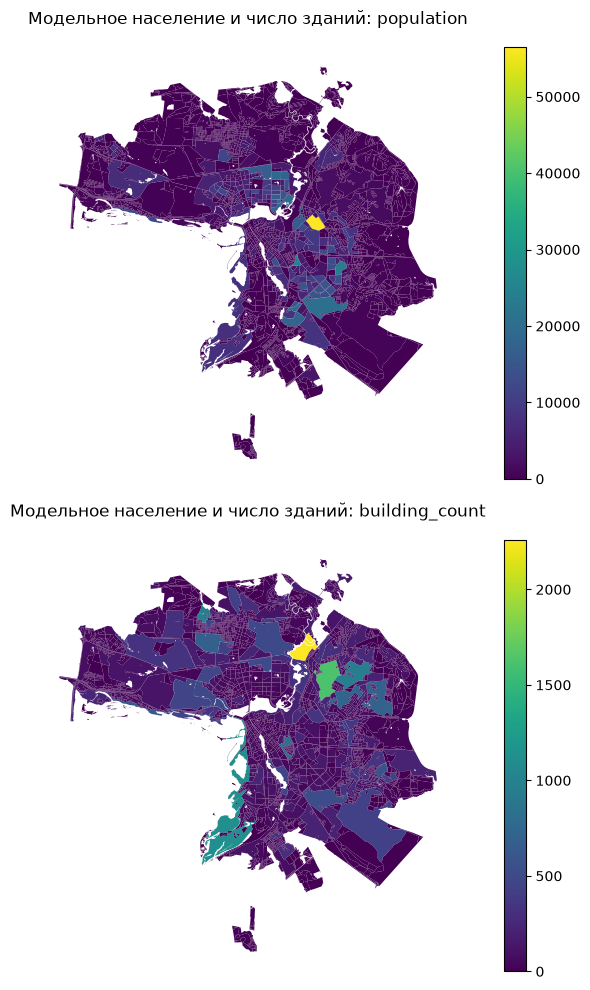

In [28]:
require_review()

plot_columns(buildings_blocks, ['population', 'building_count'], 'Модельное население и число зданий');
save_layer(buildings_blocks, datafile('kazan_buildings_blocks.geojson'), 'block_id')
save_layer(buildings, datafile('kazan_buildings.geojson'))

## 7. Школы: количество и вместимость

Учебный пример рассчитывает школы. Дополнительные типы учреждений в эту работу не добавляем.
Очевидные дубли точки и полигона одной школы проверяются. При неизвестной вместимости
`impute_services` использует 250 мест — минимальную единицу из конфигурации, а не наблюдаемое значение.
Сохраняются признаки оценённой вместимости. Количество объектов OSM может отличаться от официального числа школ.

2026-10-28 02:23:52.300 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-28 02:23:52.302 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Школ: 237 | Вместимость оценена у: 237


,school_count,school_capacity,capacity_estimated_count
0,0.0,0.0,0.0
1,0.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,0.0,0.0
4,0.0,0.0,0.0


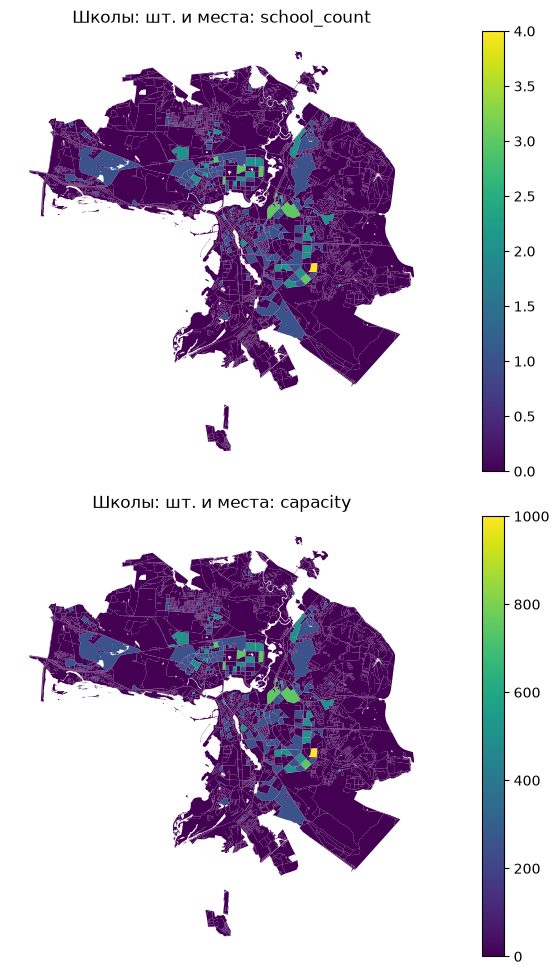

In [29]:
require_review()

from blocksnet.preprocessing.imputing import impute_services
raw = fetch_features(boundary_wgs, {'amenity': 'school'}, datafile('kazan_raw_schools.geojson'),
    BASE + ['capacity'], POLYGONS + ['Point']).to_crs(crs)
raw['capacity'] = numeric(raw.capacity).where(lambda x: x > 0)
raw = deduplicate_schools(raw)
missing_capacity = raw.capacity.isna()
schools = impute_services(raw[['geometry', 'capacity']], 'school')
schools['capacity'] = schools.capacity.round().astype(int)
schools['capacity_estimated_count'] = missing_capacity.astype(int)
schools['name'] = raw['name']
schools_blocks, unmatched_schools = aggregate_objects(blocks[['geometry']].copy(), schools)
schools_blocks = schools_blocks.rename(columns={'count': 'school_count'})
if schools_blocks.school_count.sum() + len(unmatched_schools) != len(schools):
    raise ValueError('Школы повторно отнесены к нескольким кварталам. Нужна проверка.')
services_blocks = {'school': schools_blocks}
services_raw = {'school': schools.assign(service_type='school')}
services_df = schools_blocks[['school_count', 'capacity', 'capacity_estimated_count']].rename(columns={'capacity': 'school_capacity'})
save_layer(unmatched_schools, datafile('kazan_schools_unmatched.geojson'))
print('Школ:', len(schools), '| Вместимость оценена у:', int(missing_capacity.sum()))
display(services_df.head())
plot_columns(schools_blocks, ['school_count', 'capacity'], 'Школы: шт. и места');

In [39]:
require_review()

services_gdf_all = services_raw['school']
save_layer(services_gdf_all, datafile('kazan_services.geojson'))
save_layer(schools_blocks, datafile('kazan_schools_blocks.geojson'), 'block_id')
services_df.to_csv(datafile('kazan_services_blocks.csv'))

## 8. Обеспеченность школами

Параметры библиотеки: 120 мест на 1000 жителей и 15 минут. В нашей работе время автомобильное,
поэтому это сценарная оценка, а не подтверждение пешеходной доступности или выполнения нормативов.
`demand` — модельная потребность, `demand_left` — нераспределённая потребность;
`capacity_left` — оставшиеся места. `*_within` и `*_without` разделяют распределение в пределах
порога и за ним. `provision_strong` учитывает обеспеченный спрос в пределах порога,
`provision_weak` — всё распределение, включая места за порогом. Обе величины — доли 0–1.
При стандартном `max_depth=1` внешняя зона не расширяется, поэтому показатели могут совпадать.

In [30]:
require_review()

from blocksnet.analysis.provision import competitive_provision
from blocksnet.config import service_types_config
school_params = service_types_config['school']
school_demand = int(school_params['demand'])
school_accessibility = int(school_params['accessibility'])
df_school = buildings_blocks[['population']].join(schools_blocks[['capacity']])
prov_school, links_school = competitive_provision(df_school, acc_mx, school_accessibility,
    demand=school_demand, max_depth=1)
display(prov_school.head())
save_layer(blocks[['geometry']].join(prov_school), datafile('kazan_school_provision.geojson'), 'block_id')
links_school.to_csv(datafile('kazan_school_links.csv'))
save_layer(provision_links_geojson(links_school, blocks), datafile('kazan_school_links.geojson'))
print('Линии распределения в GeoJSON обозначают связи между кварталами, а не фактические маршруты.')

2026-10-28 02:25:47.879 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-28 02:25:47.880 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-28 02:25:47.888 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-28 02:25:47.923 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-28 02:25:50.793 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
0,55,0,55,0,0,0,0,0,0.0,0.0
1,0,0,0,0,0,0,0,0,NaN,NaN
2,34,0,34,0,0,0,0,0,0.0,0.0
3,0,0,0,0,0,0,0,0,NaN,NaN
4,1,0,1,0,0,0,0,0,0.0,0.0


Линии распределения в GeoJSON обозначают связи между кварталами, а не фактические маршруты.


value
source target       
28     2859    250.0
60     304      45.0
62     903     126.0
       1082     45.0
       1214     37.0

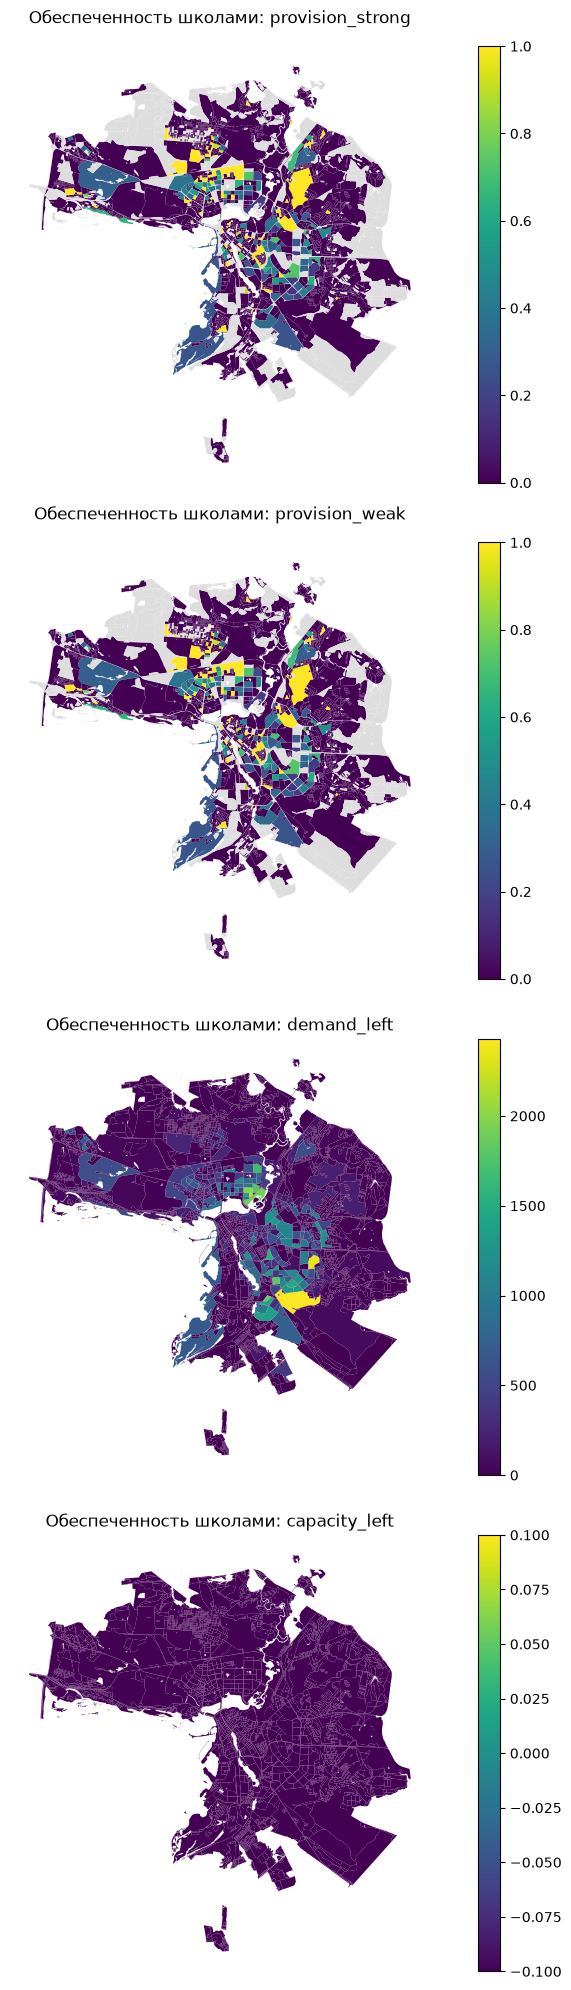

In [31]:
require_review()

plot_columns(blocks[['geometry']].join(prov_school), ['provision_strong', 'provision_weak', 'demand_left', 'capacity_left'],
             'Обеспеченность школами');
display(links_school.head())

## 9. Сохранение результатов обеспеченности

Сохраняем все столбцы оценки школ. Показатели учреждений с разными единицами не усредняются.

In [32]:
require_review()

prov_all = pd.DataFrame({'school': prov_school.provision_strong})
display(prov_school.describe().T)

,count,mean,std,min,25%,50%,75%,max
demand,5159.0,45.035084,220.013304,0.0,0.0,0.0,5.0,6779.0
capacity,5159.0,11.484784,64.384861,0.0,0.0,0.0,0.0,1000.0
demand_left,5159.0,33.550300,154.709238,0.0,0.0,0.0,4.0,2430.0
demand_within,5159.0,11.484784,120.382759,0.0,0.0,0.0,0.0,6779.0
demand_without,5159.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
capacity_left,5159.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
capacity_within,5159.0,3.501648,30.149054,0.0,0.0,0.0,0.0,496.0
capacity_without,5159.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
provision_strong,1965.0,0.065070,0.222566,0.0,0.0,0.0,0.0,1.0
provision_weak,1965.0,0.065070,0.222566,0.0,0.0,0.0,0.0,1.0


In [33]:
require_review()

mean_provision = prov_school.provision_strong.rename('school_provision')
prov_school.to_csv(datafile('kazan_provision_school.csv'))
save_layer(blocks[['geometry']].join(mean_provision), datafile('kazan_blocks_provision.geojson'), 'block_id')

## 10. Плотность и два способа классификации застройки

FSI = площадь этажей / площадь квартала; GSI = пятно зданий / площадь квартала;
MXI = жилые площади / все площади этажей; L = площадь этажей / пятно зданий;
OSR = открытая площадь / площадь этажей. `share_living` и `share_non_living` в этой версии
также делятся на пятно зданий и могут превышать 1. Эти индексы не являются населением на гектар.
Spacematrix группирует застройку по FSI, L, MXI; «Стрелка» использует свои правила по тем же характеристикам.
Кварталы без определимых характеристик остаются без типа, а не получают выдуманную категорию.

In [34]:
require_review()

from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
buildings_blocks['site_area'] = buildings_blocks.area.astype(float)
density_df = calculate_density_indicators(buildings_blocks)
valid = (density_df.fsi > 0) & np.isfinite(density_df[['fsi', 'l', 'mxi']]).all(axis=1)
if not valid.any():
    raise ValueError('Нет застройки с определимыми характеристиками. Проверь исходные данные.')
morph_input = density_df.loc[valid, ['fsi', 'l', 'mxi']]
cluster_count = min(11, len(morph_input.drop_duplicates()))
spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(morph_input, n_clusters=cluster_count, random_state=42)
strelka_df = get_strelka_morphotypes(morph_input)
spacematrix_df = spacematrix_df.reindex(blocks.index)
strelka_df = strelka_df.reindex(blocks.index)
print('Кластеров Spacematrix:', cluster_count, '(в примере 11; меньше — только при нехватке разных наблюдений)')
display(density_df.head())
display(spacematrix_clusters)
display(strelka_df.morphotype.value_counts(dropna=False))

Кластеров Spacematrix: 11 (в примере 11; меньше — только при нехватке разных наблюдений)


,site_area,footprint_area,build_floor_area,living_area,non_living_area,fsi,gsi,mxi,l,osr,share_living,share_non_living
0,2.839669e+06,72005.877796,95367.378998,13763.147561,81604.231437,0.033584,0.025357,0.144317,1.324439,29.021065,0.191139,1.133300
1,5.506961e+04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN
2,3.486062e+05,14752.218315,18002.746728,9241.755524,8760.991204,0.051642,0.042318,0.513353,1.220342,18.544611,0.626465,0.593876
3,3.178583e+04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN
4,4.107708e+05,20418.524066,20418.524066,227.620473,20190.903593,0.049708,0.049708,0.011148,1.000000,19.117554,0.011148,0.988852


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.000000,0.141087,0.874366,low-rise,low-density,residential,low-rise low-density residential
1,1.000000,0.128705,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
2,7.121303,1.111844,0.820145,high-mid-rise,None,residential,high-mid-rise residential
3,4.569230,3.748931,0.000000,mid-rise,high-density,non-residential,mid-rise high-density non-residential
4,4.309243,0.787547,0.775598,mid-rise,low-density,residential,mid-rise low-density residential
5,1.102504,0.128194,0.261437,low-rise,low-density,mixed-use,low-rise low-density mixed-use
6,12.857062,2.159428,0.829786,high-rise,high-density,residential,high-rise high-density residential
7,3.139660,0.928676,0.072120,mid-rise,low-density,non-residential,mid-rise low-density non-residential
8,18.296728,5.987863,0.876661,tower,high-density,residential,tower high-density residential


morphotype
NaN                               2401
low-rise model                    1165
low-rise non-residential           875
individual residential             359
mid-rise                           231
mid-rise non-residential            33
central model                       31
high-rise modern microdistrict      28
high-rise soviet microdistrict      17
high-rise non-residential           10
mid-rise block                       7
mid-rise microdistrict               2
Name: count, dtype: int64

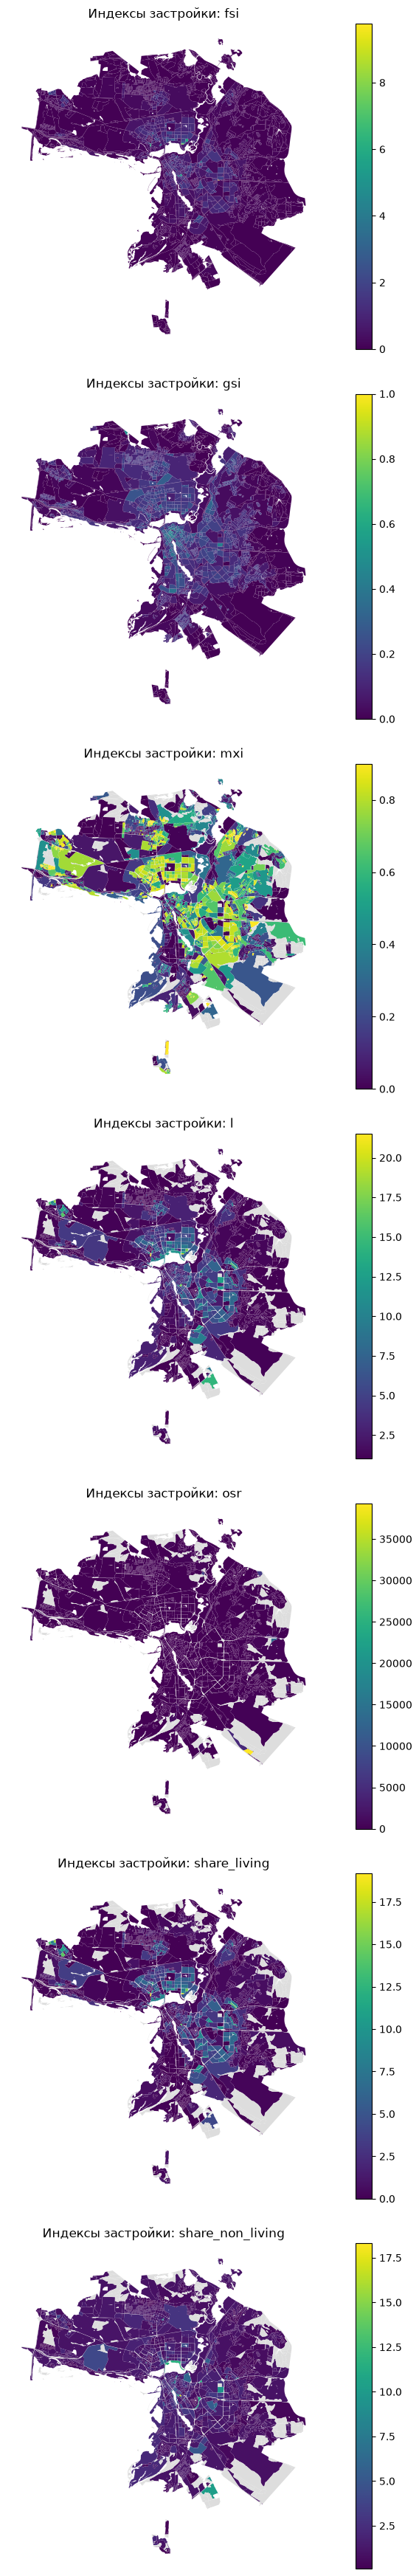

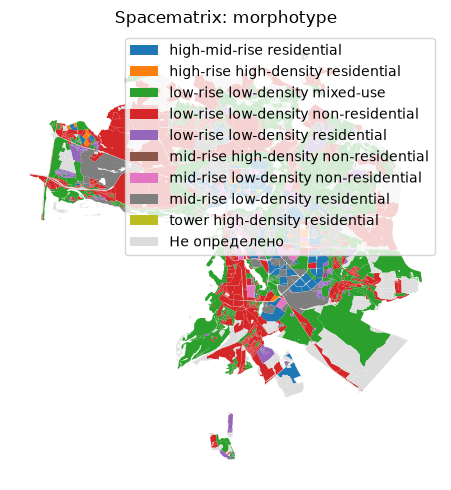

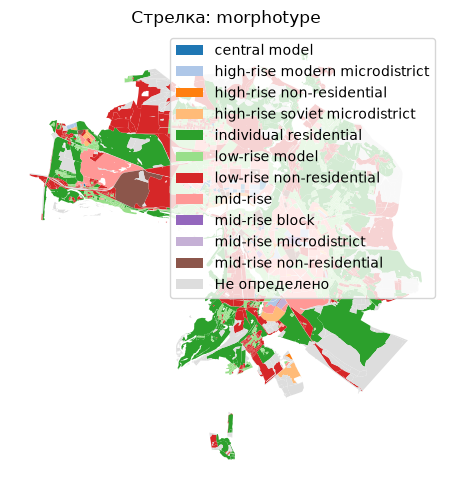

In [35]:
require_review()

plot_columns(blocks[['geometry']].join(density_df), ['fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living'], 'Индексы застройки');
plot_columns(blocks[['geometry']].join(spacematrix_df[['morphotype']]), ['morphotype'], 'Spacematrix');
plot_columns(blocks[['geometry']].join(strelka_df[['morphotype']]), ['morphotype'], 'Стрелка');
density_df.to_csv(datafile('kazan_density_metrics.csv'))
spacematrix_clusters.to_csv(datafile('kazan_spacematrix_clusters.csv'))
save_layer(blocks[['geometry']].join(density_df), datafile('kazan_density_metrics.geojson'), 'block_id')
morphs = blocks[['geometry']].join(spacematrix_df[['cluster', 'morphotype']].add_prefix('spacematrix_'))
morphs = morphs.join(strelka_df.morphotype.rename('strelka'))
save_layer(morphs, datafile('kazan_blocks_morphotypes.geojson'), 'block_id')

## 11. Доступность с учётом площади

`area_accessibility` — среднее время до остальных кварталов с весами по их площади, в минутах.
Это не расстояние до географического центра. В нашем случае используется автомобильное время.
Меньшее значение означает меньшую среднюю удалённость от площади исследуемой территории.

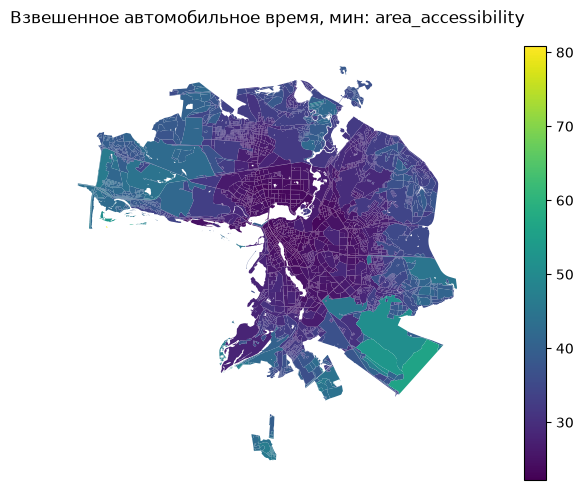

In [36]:
require_review()

from blocksnet.analysis.network.accessibility import area_accessibility
area_acc = area_accessibility(acc_mx, buildings_blocks)
plot_columns(blocks[['geometry']].join(area_acc), ['area_accessibility'], 'Взвешенное автомобильное время, мин');
area_acc.to_csv(datafile('kazan_area_accessibility.csv'))
save_layer(blocks[['geometry']].join(area_acc), datafile('kazan_blocks_accessibility.geojson'), 'block_id')

## 12. Проверка полноты и ограничений

Проверяем восемь групп из учебного примера. Подробные таблицы сохраняют все исходные поля
результатов, карты показывают ключевые показатели. Модельные оценки отделены от наблюдений.
Перед дашбордом обсудим реальные выводы, пропуски OSM и покрытие транспортного графа.

In [40]:
require_review()

groups = pd.DataFrame([
    ['Землепользование: 7 долей, главная функция и её доля', 'kazan_blocks_landuse.geojson'],
    ['Время в пути: матрица мин и сводные времена', 'kazan_acc_mx.parquet'],
    ['Здания: количество, площади, этажность, население, оценки', 'kazan_buildings_blocks.geojson'],
    ['Школы: количество, вместимость, признак оценки', 'kazan_schools_blocks.geojson'],
    ['Обеспеченность: оба показателя, потребность, места, распределение', 'kazan_school_provision.geojson'],
    ['Плотность: все 7 индексов', 'kazan_density_metrics.geojson'],
    ['Морфотипы: оба метода и характеристики кластеров', 'kazan_blocks_morphotypes.geojson'],
    ['Доступность с весами по площади, мин', 'kazan_blocks_accessibility.geojson'],
], columns=['Группа', 'Файл'])
groups['Файл существует'] = groups['Файл'].map(lambda name: datafile(name).exists())
display(groups)
assert groups['Файл существует'].all(), 'Не все расчёты выполнены.'
raw_data_sources = {p.name: json.loads(p.read_text(encoding='utf-8'))
                    for p in Path(DATA_DIR).glob('kazan_raw_*.geojson.source.json')}
write_json({'raw_data_sources': raw_data_sources, 'city': CITY_NAME, 'blocksnet': version('blocksnet'), 'mode': 'drive',
    'school_demand_per_1000': school_demand, 'school_threshold_min': school_accessibility,
    'living_demand_m2_per_person': 30, 'unknown_floors_default': 1, 'living_area_coefficient': 0.9,
    'school_capacity_imputed': int(schools.capacity_estimated_count.sum()),
    'building_floors_imputed': int(buildings.floors_imputed_count.sum()),
    'building_use_unknown': int(buildings.unknown_use_count.sum()),
    'graph_source': overture_network.SOURCE, 'graph_release': overture_network.RELEASE,
    'graph_metadata': json.loads(datafile('kazan_overture_drive.graphml.source.json').read_text(encoding='utf-8')),
    'long_connectors_over_1km': far_count,
    'limitations': ['OSM completeness', 'model population and school capacity', 'drive scenario without congestion',
                    'straight first/last mile connectors', 'Overture car network; conditional access and turn restrictions not fully modelled']},
    datafile('kazan_methodology.json'))

,Группа,Файл,Файл существует
0,"Землепользование: 7 долей, главная функция и е...",kazan_blocks_landuse.geojson,True
1,Время в пути: матрица мин и сводные времена,kazan_acc_mx.parquet,True
2,"Здания: количество, площади, этажность, населе...",kazan_buildings_blocks.geojson,True
3,"Школы: количество, вместимость, признак оценки",kazan_schools_blocks.geojson,True
4,"Обеспеченность: оба показателя, потребность, м...",kazan_school_provision.geojson,True
5,Плотность: все 7 индексов,kazan_density_metrics.geojson,True
6,Морфотипы: оба метода и характеристики кластеров,kazan_blocks_morphotypes.geojson,True
7,"Доступность с весами по площади, мин",kazan_blocks_accessibility.geojson,True


In [41]:
require_review()

final_blocks = blocks.copy()
density_columns = ['fsi', 'gsi', 'mxi', 'l', 'osr', 'share_living', 'share_non_living']
tables = [buildings_blocks.drop(columns='geometry'), services_df, prov_school.add_prefix('school_'),
          density_df[density_columns].add_prefix('dens_'),
          spacematrix_df[['cluster', 'morphotype']].add_prefix('spacematrix_'),
          strelka_df.morphotype.rename('strelka_morphotype'), area_acc, travel_summary]
for table in tables:
    if isinstance(table, pd.Series):
        table = table.to_frame()
    new_columns = [c for c in table if c not in final_blocks]
    final_blocks = final_blocks.join(table[new_columns])
save_layer(final_blocks, datafile('kazan_blocks_final.geojson'), 'block_id')
groups.to_csv(datafile('kazan_pipeline_coverage.csv'), index=False)
print('Сохранено кварталов с результатами:', len(final_blocks))

Сохранено кварталов с результатами: 5159


In [42]:
require_review()

print('Сохранённые файлы:')
for file in sorted(Path(DATA_DIR).glob('kazan*')):
    if file.is_file():
        print(file.name, f'{file.stat().st_size / 1024:,.0f} КБ')

Сохранённые файлы:
kazan-5901.graphml 10,126 КБ
kazan-5901.graphml.source.json 0 КБ
kazan_acc_mx.csv 252,282 КБ
kazan_acc_mx.parquet 148,790 КБ
kazan_acc_mx.parquet.cache.json 0 КБ
kazan_area_accessibility.csv 122 КБ
kazan_blocks.geojson 13,779 КБ
kazan_blocks.geojson.cache.json 0 КБ
kazan_blocks_accessibility.geojson 14,034 КБ
kazan_blocks_final.geojson 22,238 КБ
kazan_blocks_landuse.geojson 15,116 КБ
kazan_blocks_morphotypes.geojson 14,432 КБ
kazan_blocks_preview.html 12,761 КБ
kazan_blocks_provision.geojson 13,955 КБ
kazan_boundaries.geojson 305 КБ
kazan_boundaries.geojson.source.json 0 КБ
kazan_boundary_preview.html 94 КБ
kazan_buildings.geojson 122,287 КБ
kazan_buildings_blocks.geojson 15,781 КБ
kazan_buildings_unmatched.geojson 12 КБ
kazan_density_metrics.csv 691 КБ
kazan_density_metrics.geojson 15,861 КБ
kazan_graph_coverage.geojson 15,497 КБ
kazan_graph_coverage_review.png 338 КБ
kazan_land_use_shares.csv 1 КБ
kazan_landuse_ru.png 278 КБ
kazan_methodology.json 8 КБ
kazan_object

## 13. Выводы по Казани

Выводы сформулированы по сохранённым результатам расчётов. Все числа относятся к учебной модели.

1. Исследование охватывает всю выбранную границу Казани: сохранены 5 159 кварталов. Они построены по дорогам, воде и железным дорогам OSM и могут отличаться от официальных кварталов.

2. Жилая функция преобладает в 2301 квартале и занимает 40,7 % суммарной площади кварталов. У 2 002 кварталов (38,8 %) функция не определена; по площади это 11,4 %. Отсутствие тега OSM не означает отсутствие функции.

3. В кварталы отнесены 102 495 зданий. Модель дала 1 928 159 жителей при 30 м² жилой площади на человека. У 74 189 зданий этажность восстановлена, у 61 926 не уточнён тип. Численность нельзя выдавать за официальную статистику.

4. Найдены 237 объектов школ OSM. Вместимость всех объектов оценена как 250 мест: суммарно 59 250 условных мест. Главное ограничение — отсутствие наблюдаемых вместимостей, возможные ошибки классификации и дубли в OSM.

5. В сценарии обеспеченности распределено 59 250 мест из 232 336 модельной потребности (25,5 %). Это отношение суммарного обеспеченного спроса к суммарному спросу, а не среднее долей кварталов. Результат не доказывает реальную нехватку мест и не определяет места строительства школ.

6. По сохранённой матрице среднее время между кварталами — 26,2 мин. Все пары достижимы. Используется автомобильная сеть Overture без пробок и прямые подходы 5 км/ч; у 11 кварталов подход длиннее 1 км.

7. FSI различается от 0,00 до 9,76, медиана — 0,024. Высокие значения обозначают концентрацию площади этажей относительно площади квартала; сравнение зависит от размера и границ кварталов.

8. В Spacematrix получено 11 кластеров. Обе классификации определены у 2 758 кварталов; у 2 401 (46,5 %) тип не определён из-за отсутствия подходящих характеристик застройки.

9. Время с весами по площади лежит в диапазоне 22,2–80,8 мин. Меньшее значение означает меньшую среднюю удалённость от площади территории. Для объяснения причин различий нужны проверка данных и локальное знание города.

### Что я могу объяснить при сдаче

- **Почему население модельное?** Оно восстановлено из жилой площади и этажности с допущением 30 м²/чел; в OSM есть пропуски и неизвестные типы зданий.
- **Почему нельзя утверждать, что городу не хватает именно столько школьных мест?** Всем школам назначена условная вместимость 250 мест, а потребность рассчитана от модельного населения. Для реального вывода нужны фактические вместимости, контингент, полный реестр и подходящий способ передвижения.
- **Чем отличаются два времени?** Среднее время до кварталов даёт всем кварталам равный вес. Доступность по площади даёт больший вес более крупным кварталам.
- **Что означает серый цвет?** Показатель или тип не определён; при нулевом спросе обеспеченность не заменяется нулём.

![Обзор сохранённых результатов Казани](kazan_overview.png)

Статический обзор отрисован из сохранённых GeoJSON, без повторного расчёта показателей. Полная интерактивная карта находится в `../dashboard.html`.


## 14. Дашборд, проверка и сдача

Готовая страница: **`dashboard.html` в корне проекта**. Она содержит 47 показателей по 8 группам, карту всех кварталов, графики, таблицы, характеристики 11 кластеров, распределение школьных мест, источники и ограничения. Полная матрица 5159 × 5159 хранится отдельно; в HTML показан явно подписанный фрагмент, а не подмена полной матрицы.

### Повторная сборка HTML из сохранённых результатов

В PowerShell из папки проекта:

```powershell
.venv\Scripts\python.exe make_dashboard.py
```

Сборка читает `examples/data`, оформляет сохранённые значения и не загружает данные, не пересчитывает кварталы, сеть, матрицу или показатели BlocksNet. Для просмотра открой `dashboard.html` двойным щелчком либо `OPEN_DASHBOARD.cmd`. Карта кварталов, графики, таблицы и Leaflet встроены в HTML; интернет нужен для подложки OpenStreetMap.

### Если нужно повторить вычисления после перезапуска ядра

Выбери Python 3.12 из `.venv` и выполняй ячейки сверху по очереди. Сохранённые исходные GeoJSON читаются повторно; граф и матрица используют проверяемый кэш. После перезапуска снова выполни ячейку принятия карты в разделе остановки. Не удаляй данные и не устанавливай FORCE_RECALCULATE=True без необходимости. Расчёты запускает студент.

### Проверка полноты относительно pipeline.ipynb

| Показатели | Ноутбук | Дашборд |
|---|---|---|
| 7 долей функций, преобладающая функция, её доля | 4 | Карта, график площади, все столбцы таблицы |
| Матрица времени, среднее и медианное время, подходы | 5А–5Б | Карта, график, таблица кварталов; подписанный фрагмент матрицы |
| Количество зданий, население, площади, этажность, признаки восстановления | 6 | Карта, график, все столбцы таблицы |
| Школы: количество, вместимость, признак оценки | 7 | Карта кварталов и объектов, график, таблица |
| Потребность, оба показателя обеспеченности, остатки, within/without и связи | 8–9 | Карта, график, таблицы кварталов и всех связей |
| FSI, GSI, MXI, L, OSR, share_living, share_non_living | 10 | Все 7 карт, гистограмм и столбцов |
| Spacematrix, «Стрелка», номер кластера, характеристики всех групп | 10 | Обе карты, графики, таблицы кварталов и кластеров |
| Доступность с весами по площади | 11 | Карта, график, таблица |

### Сдача

Форма преподавателя: https://forms.yandex.ru/cloud/6ad22113c45c078cec3c7c7d/

Введи своё ФИО и прикрепи **`dashboard.html`**, не папку и не ZIP. Лимит формы — 20 МБ; готовый HTML укладывается в него. Укажи ссылку на свой репозиторий GitHub с проектом. В репозитории должны быть выполненный ноутбук, код сборки, данные или ссылка на архив данных, HTML и зависимости. `SUBMISSION.txt` содержит точные поля формы и пояснение ограничений. Крупные данные собраны отдельно в `submission/kazan_homework_complete.zip`; публикация архива требует проверенной ссылки.

Запрос последнего этапа: «Сделай последний этап с выводами, дашбордом и сдачей». Агент проверил уже сохранённые результаты и подготовил оформление; новые расчёты исследования не запускались. Отправка считается завершённой только после сообщения об успешной отправке формы.
